# Report Figures for Part I Sections 1-3

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
Path("figures").mkdir(exist_ok=True)

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 10,
})

SMOOTH_WINDOW = 100
RAW_ALPHA = 0.2
RAW_LINEWIDTH = 0.35
SMOOTH_LINEWIDTH = 2.0
KL_YLIM = (-0.04, 1.2)

RUN_LABELS = [
    "v1 (K=2 + original reward)",
    "v2 (K=8 + original reward)",
    "v3 (K=8 + format downweight)",
    "v4 (K=8 + reward recalibration)",
]

COLORS = {
    "v1 (K=2 + original reward)": "#1372b6",
    "v2 (K=8 + original reward)": "#c70606",
    "v3 (K=8 + format downweight)": "#f5821e",
    "v4 (K=8 + reward recalibration)": "#0ea511",
}

In [3]:
reward_raw = pd.read_csv("measurement/reward.csv")
reward_df = pd.DataFrame({
    "Step": pd.to_numeric(reward_raw["Step"]),
    "v1 (K=2 + original reward)": pd.to_numeric(reward_raw["final_baseline_100 - rewards/train/score/mean"]),
    "v2 (K=8 + original reward)": pd.to_numeric(reward_raw["final_improve_k8_100 - rewards/train/score/mean"]),
    "v3 (K=8 + format downweight)": pd.to_numeric(reward_raw["final_improve_reward_reweighted_ef0-5_af0-5 - rewards/train/score/mean"]),
    "v4 (K=8 + reward recalibration)": pd.to_numeric(reward_raw["final_improve_reward_v2_100 - rewards/train/score/mean"]),
})

kl_raw = pd.read_csv("measurement/kl.csv")
kl_df = pd.DataFrame({
    "Step": pd.to_numeric(kl_raw["Step"]),
    "v1 (K=2 + original reward)": pd.to_numeric(kl_raw["final_baseline_100 - actor/train/kl"]),
    "v2 (K=8 + original reward)": pd.to_numeric(kl_raw["final_improve_k8_100 - actor/train/kl"]),
    "v3 (K=8 + format downweight)": pd.to_numeric(kl_raw["final_improve_reward_reweighted_ef0-5_af0-5 - actor/train/kl"]),
    "v4 (K=8 + reward recalibration)": pd.to_numeric(kl_raw["final_improve_reward_v2_100 - actor/train/kl"]),
})

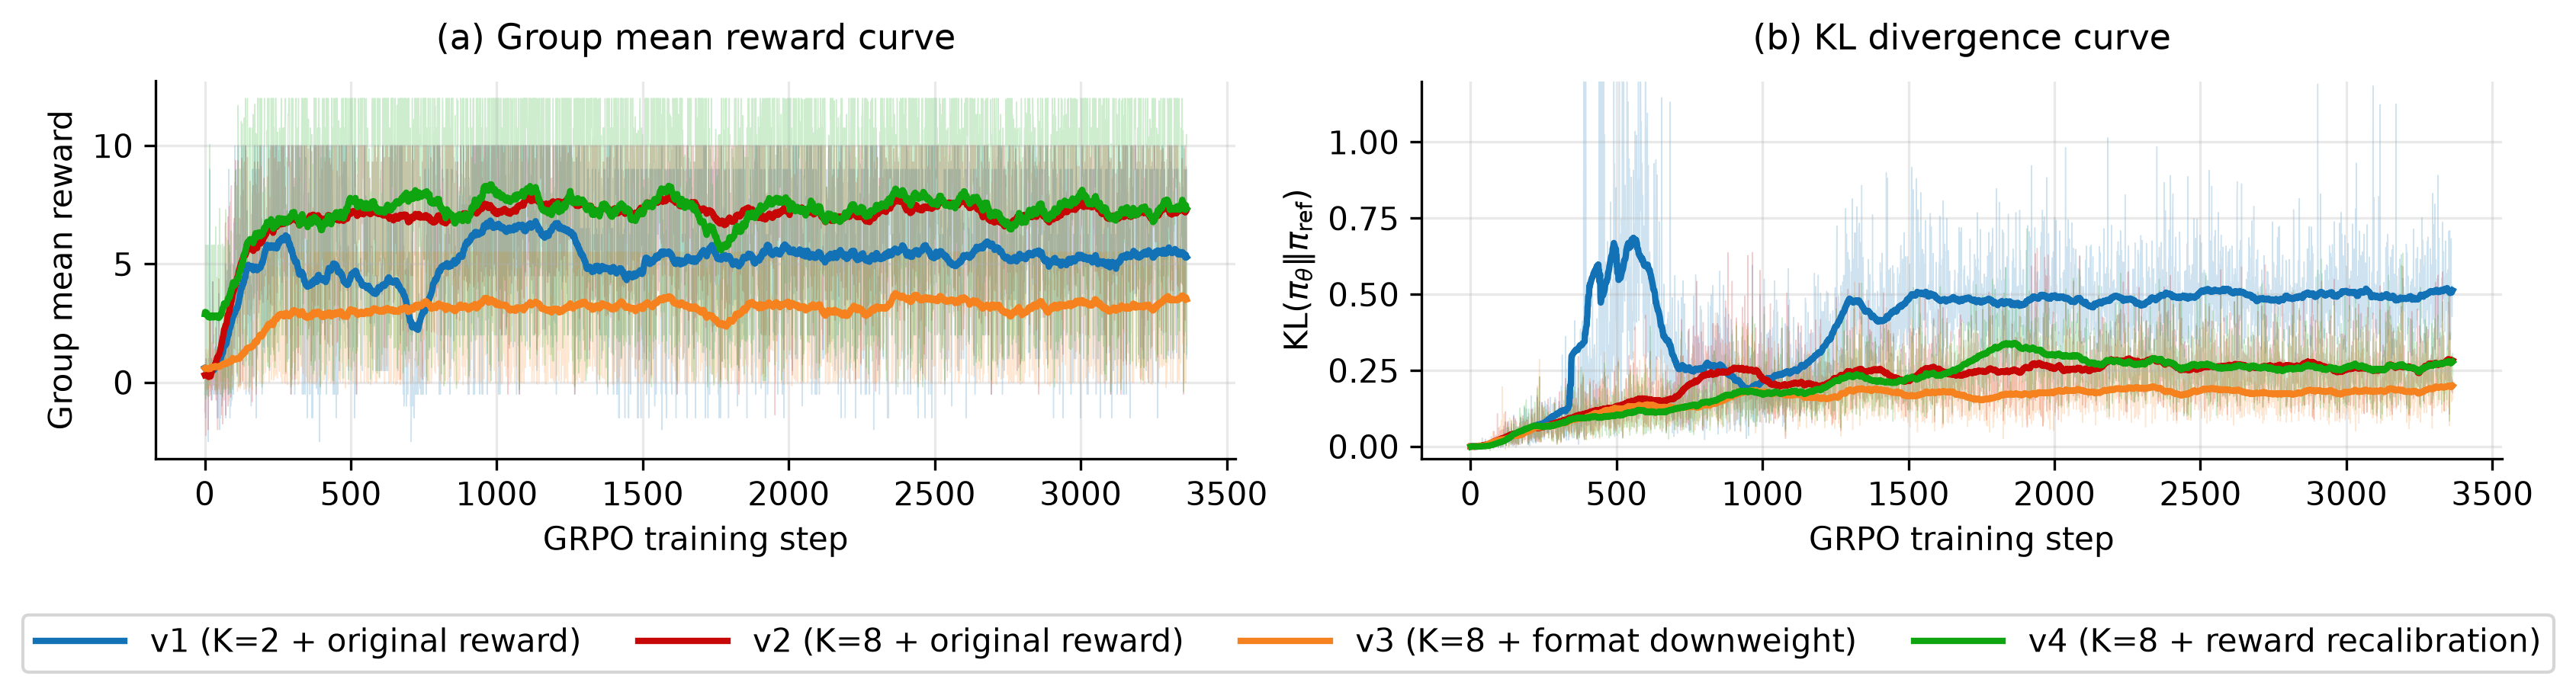

In [4]:
fig, (ax_reward, ax_kl) = plt.subplots(1, 2, figsize=(11.2, 3.0), dpi=300)

for label in RUN_LABELS:
    ax_reward.plot(
        reward_df["Step"],
        reward_df[label],
        color=COLORS[label],
        linewidth=RAW_LINEWIDTH,
        alpha=RAW_ALPHA,
        zorder=1,
    )
    ax_reward.plot(
        reward_df["Step"],
        reward_df[label].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean(),
        label=label,
        color=COLORS[label],
        linewidth=SMOOTH_LINEWIDTH,
        zorder=2,
    )
    ax_kl.plot(
        kl_df["Step"],
        kl_df[label],
        color=COLORS[label],
        linewidth=RAW_LINEWIDTH,
        alpha=RAW_ALPHA,
        zorder=1,
    )
    ax_kl.plot(
        kl_df["Step"],
        kl_df[label].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean(),
        label=label,
        color=COLORS[label],
        linewidth=SMOOTH_LINEWIDTH,
        zorder=2,
    )

ax_reward.set_title("(a) Group mean reward curve", pad=10)
ax_reward.set_xlabel("GRPO training step")
ax_reward.set_ylabel("Group mean reward")
ax_reward.grid(True, which="major", alpha=0.28)
ax_reward.spines["top"].set_visible(False)
ax_reward.spines["right"].set_visible(False)

ax_kl.set_title("(b) KL divergence curve", pad=10)
ax_kl.set_xlabel("GRPO training step")
ax_kl.set_ylabel(r"KL($\pi_\theta \Vert \pi_{\rm ref}$)")
ax_kl.set_ylim(*KL_YLIM)
ax_kl.grid(True, which="major", alpha=0.28)
ax_kl.spines["top"].set_visible(False)
ax_kl.spines["right"].set_visible(False)

handles, labels = ax_reward.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=4, columnspacing=1.8, handlelength=2.8)
fig.tight_layout(rect=[0, 0.12, 1, 1])
fig.savefig("figures/all_reward_kl_curves.png", dpi=300, bbox_inches="tight")

plt.show()

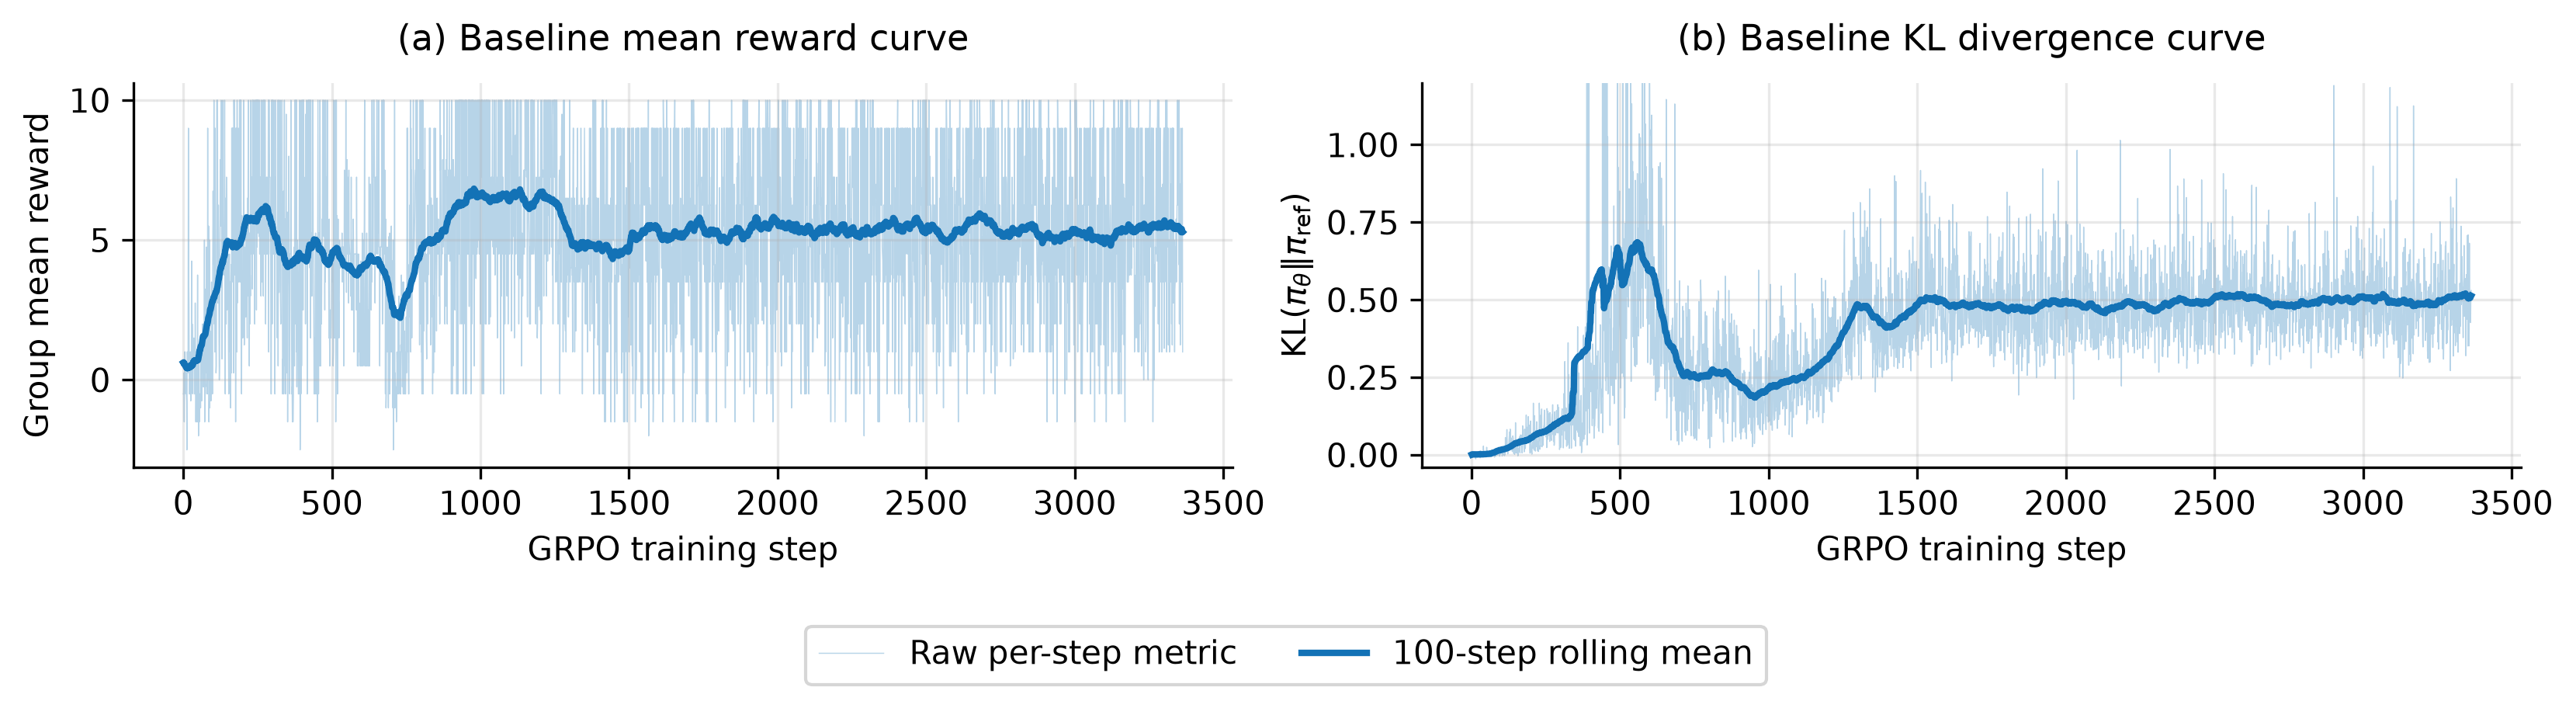

In [5]:
fig, (ax_reward, ax_kl) = plt.subplots(1, 2, figsize=(11.2, 3.0), dpi=300)
label = "v1 (K=2 + original reward)"

ax_reward.plot(
    reward_df["Step"],
    reward_df[label],
    color=COLORS[label],
    linewidth=RAW_LINEWIDTH,
    alpha=0.3,
    zorder=1,
    label="Raw per-step metric",
)
ax_reward.plot(
    reward_df["Step"],
    reward_df[label].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean(),
    color=COLORS[label],
    linewidth=SMOOTH_LINEWIDTH,
    zorder=2,
    label="100-step rolling mean",
)

ax_kl.plot(
    kl_df["Step"],
    kl_df[label],
    color=COLORS[label],
    linewidth=RAW_LINEWIDTH,
    alpha=0.3,
    zorder=1,
    label="Raw per-step metric",
)
ax_kl.plot(
    kl_df["Step"],
    kl_df[label].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean(),
    color=COLORS[label],
    linewidth=SMOOTH_LINEWIDTH,
    zorder=2,
    label="100-step rolling mean",
)

ax_reward.set_title("(a) Baseline mean reward curve", pad=10)
ax_reward.set_xlabel("GRPO training step")
ax_reward.set_ylabel("Group mean reward")
ax_reward.grid(True, which="major", alpha=0.28)
ax_reward.spines["top"].set_visible(False)
ax_reward.spines["right"].set_visible(False)

ax_kl.set_title("(b) Baseline KL divergence curve", pad=10)
ax_kl.set_xlabel("GRPO training step")
ax_kl.set_ylabel(r"KL($\pi_\theta \Vert \pi_{\rm ref}$)")
ax_kl.set_ylim(*KL_YLIM)
ax_kl.grid(True, which="major", alpha=0.28)
ax_kl.spines["top"].set_visible(False)
ax_kl.spines["right"].set_visible(False)

handles, labels = ax_reward.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=2)
fig.tight_layout(rect=[0, 0.12, 1, 1])
fig.savefig("figures/baseline_reward_kl_curves.png", dpi=300, bbox_inches="tight")
plt.show()

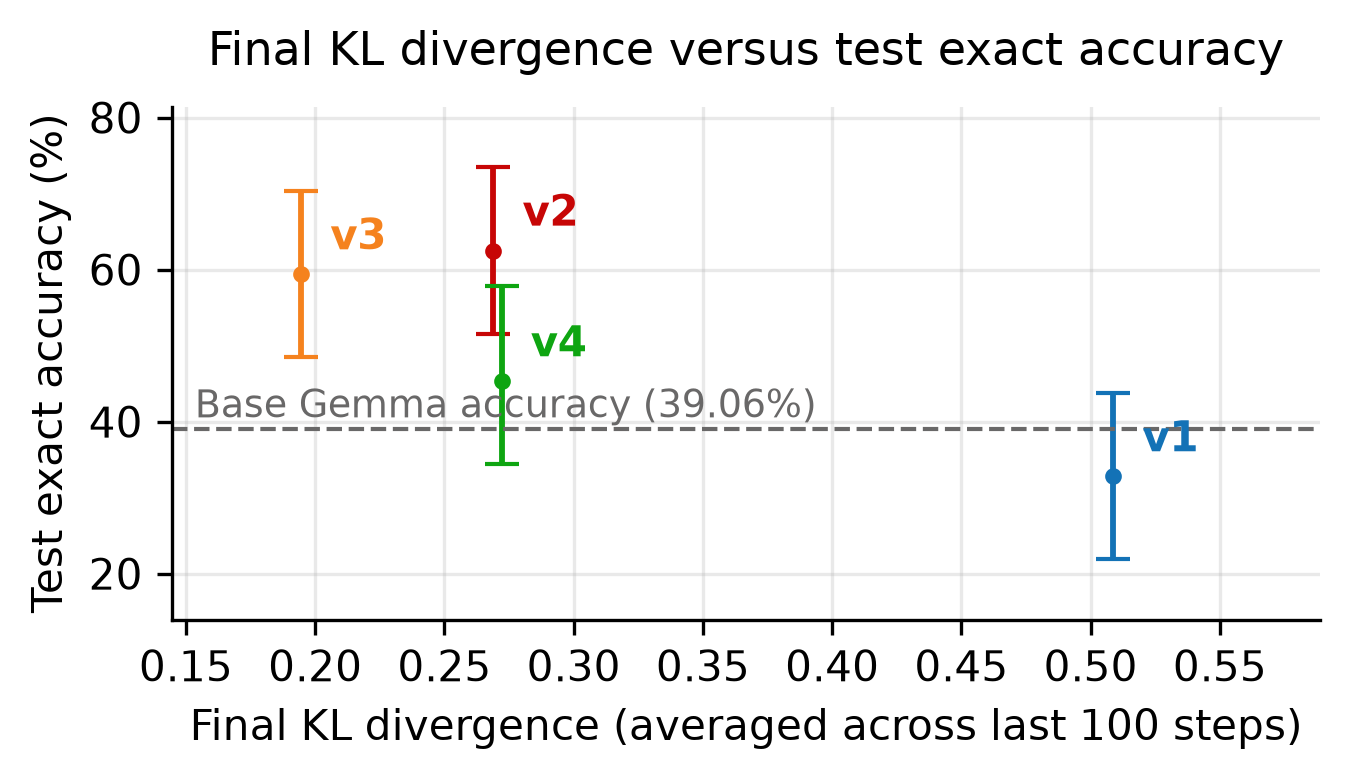

In [6]:
kl_accuracy_df = pd.DataFrame([
    {"label": "v1 (K=2 + original reward)", "short_label": "v1", "final_kl_last_window_mean": kl_df["v1 (K=2 + original reward)"].tail(100).mean(), "accuracy": 32.81, "accuracy_lower": 21.88, "accuracy_upper": 43.75},
    {"label": "v2 (K=8 + original reward)", "short_label": "v2", "final_kl_last_window_mean": kl_df["v2 (K=8 + original reward)"].tail(100).mean(), "accuracy": 62.50, "accuracy_lower": 51.56, "accuracy_upper": 73.44},
    {"label": "v3 (K=8 + format downweight)", "short_label": "v3", "final_kl_last_window_mean": kl_df["v3 (K=8 + format downweight)"].tail(100).mean(), "accuracy": 59.38, "accuracy_lower": 48.44, "accuracy_upper": 70.31},
    {"label": "v4 (K=8 + reward recalibration)", "short_label": "v4", "final_kl_last_window_mean": kl_df["v4 (K=8 + reward recalibration)"].tail(100).mean(), "accuracy": 45.31, "accuracy_lower": 34.38, "accuracy_upper": 57.81},
])

fig, ax = plt.subplots(figsize=(4.6, 2.7), dpi=300)

for _, row in kl_accuracy_df.iterrows():
    yerr = [[row["accuracy"] - row["accuracy_lower"]], [row["accuracy_upper"] - row["accuracy"]]]
    ax.errorbar(
        row["final_kl_last_window_mean"],
        row["accuracy"],
        yerr=yerr,
        fmt="o",
        markersize=3,
        color=COLORS[row["label"]],
        ecolor=COLORS[row["label"]],
        elinewidth=1.4,
        capsize=4,
        label=row["label"],
    )
    ax.annotate(
        row["short_label"],
        xy=(row["final_kl_last_window_mean"], row["accuracy"]),
        xytext=(7, 6),
        textcoords="offset points",
        fontsize=10,
        color=COLORS[row["label"]],
        weight="bold",
    )

ax.set_title("Final KL divergence versus test exact accuracy", pad=10)
ax.set_xlabel("Final KL divergence (averaged across last 100 steps)")
ax.set_ylabel("Test exact accuracy (%)")
ax.grid(True, which="major", alpha=0.28)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(kl_accuracy_df["final_kl_last_window_mean"].min() - 0.05, kl_accuracy_df["final_kl_last_window_mean"].max() + 0.08)
ax.set_ylim(kl_accuracy_df["accuracy_lower"].min() - 8, kl_accuracy_df["accuracy_upper"].max() + 8)
BASE_GEMMA_ACCURACY = 39.06
ax.axhline(BASE_GEMMA_ACCURACY, color="#696868", linestyle="--", linewidth=1.0)
ax.text(0.02, BASE_GEMMA_ACCURACY + 1.5, "Base Gemma accuracy (39.06%)", transform=ax.get_yaxis_transform(), fontsize=9, color="#696868")
fig.tight_layout()
fig.savefig("figures/diagnostic.png", dpi=300, bbox_inches="tight")
plt.show()